
# Bellabeat Case Study: How Can a Wellness Company Play It Smart?
*Analyzing Fitbit activity and sleep data using Python to identify potential marketing opportunities for Bellabeat.*

## 1. Ask — Business Task

### Business Overview

Bellabeat is a health-focused technology company that creates smart wellness products for women. The company is looking for opportunities to grow its presence in the smart device market by better understanding how consumers use fitness trackers.

### Business Task

As a junior data analyst on Bellabeat's marketing analytics team, my goal is to analyze consumer fitness tracker data to identify trends in physical activity and sleep habits.

I'll focus on how these trends could apply to Bellabeat's Leaf wellness tracker and use the findings to develop three data-driven marketing recommendations. The goal is to help Bellabeat better connect with its target audience and identify opportunities for growth.

### Key Business Questions

1. What trends can be identified in smart device usage?
2. How might these trends relate to Bellabeat customers?
3. How could these insights influence Bellabeat's marketing strategy?

### Key Stakeholders

- **Urška Sršen:** Bellabeat cofounder and Chief Creative Officer
- **Sando Mur:** Bellabeat cofounder and executive team member
- **Bellabeat Marketing Analytics Team:** Responsible for analyzing consumer data and developing recommendations
- **Bellabeat Executive Team:** Responsible for evaluating the findings and marketing recommendations

### Product Focus

This analysis focuses on the Bellabeat Leaf, a wearable wellness tracker that monitors activity, sleep, and stress. The Fitbit dataset provides activity and sleep measurements that may help identify consumer behavior patterns relevant to marketing the Leaf.

### Tools and Data

For this case study, I used Python in JupyterLab to clean, organize, and analyze Fitbit activity and sleep data. I used pandas for data preparation and analysis and Matplotlib to create visualizations that highlight patterns in the data.

The dataset includes daily activity records from 33 Fitbit participants and sleep records from 24 participants, collected over approximately one month in 2016.

Because this is a small, historical dataset, the findings are intended to identify potential trends and marketing opportunities rather than represent the behaviors of all Bellabeat customers.


## 2. Prepare — Data Sources

### Data Source

For this analysis, I am using the Fitbit Fitness Tracker Data dataset, made available by Möbius on Kaggle. The dataset contains fitness tracker information collected from approximately 30 Fitbit users who consented to sharing their data.

The dataset includes information about daily physical activity, steps, calories, and sleep patterns. These measurements will help me explore how people use fitness tracking devices and identify trends that could be useful for Bellabeat's marketing strategy.

**Dataset:** Fitbit Fitness Tracker Data

**Source:** [Kaggle — Fitbit Fitness Tracker Data (Möbius)](https://www.kaggle.com/datasets/arashnic/fitbit)

**License:** CC0: Public Domain

### Files Selected for Analysis

I will begin with two CSV files:

**1. dailyActivity_merged.csv**

This file contains daily activity measurements, including:
- Total daily steps
- Distance traveled
- Activity intensity and duration
- Sedentary minutes
- Calories burned

**2. sleepDay_merged.csv**

This file contains sleep-related measurements, including:
- Sleep dates
- Total sleep records
- Total minutes asleep
- Total time in bed

These two datasets will allow me to examine activity and sleep habits separately and explore potential relationships between them.

### Data Organization

The original CSV files are stored in the `data/raw` folder and have been kept unchanged throughout the analysis.

I used Python and pandas in JupyterLab to inspect, clean, organize, and analyze the data. The cleaned datasets were stored as DataFrames within the notebook rather than exported as separate CSV files.

I also created a `data/cleaned` folder for future use if I decide to export cleaned versions of the datasets.

### Data Limitations

There are several limitations to consider:

- The dataset contains a relatively small sample of approximately 30 Fitbit users.
- The participants may not represent Bellabeat's target audience.
- The dataset comes from Fitbit devices rather than Bellabeat products.
- The data is historical and may not reflect current consumer behavior.
- Missing or inconsistent records could affect the analysis.

Because of these limitations, I will treat the findings as exploratory insights rather than conclusions about all smart device users.

### Data Credibility

The dataset is publicly available under a CC0 license and was identified in the Bellabeat case study assignment as a suitable source for exploring smart device usage.

Before beginning the analysis, I will use Python to check the dataset's structure, date ranges, missing values, duplicate records, and consistency.


In [1]:

# Import pandas for data analysis
import pandas as pd

# Verify that pandas is working
print("Pandas imported successfully!")
print("Pandas version:", pd.__version__)


Pandas imported successfully!
Pandas version: 3.1.1


In [2]:

import os

print("Current working directory:")
print(os.getcwd())


Current working directory:
/Users/landoncole/Documents/Bellabeat_Case_Study/notebooks


In [3]:

import os

print("Files in data/raw:")
print(os.listdir("../data/raw"))


Files in data/raw:
['.DS_Store', 'mturkfitbit_export_4.12.16-5.12.16', 'mturkfitbit_export_3.12.16-4.11.16']


In [4]:

import os

folder = "../data/raw/mturkfitbit_export_4.12.16-5.12.16"

print(os.listdir(folder))


['Fitabase Data 4.12.16-5.12.16']


In [5]:

import os

folder = "../data/raw/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16"

print(os.listdir(folder))


['minuteIntensitiesWide_merged.csv', 'dailyActivity_merged.csv', 'sleepDay_merged.csv', 'heartrate_seconds_merged.csv', 'minuteIntensitiesNarrow_merged.csv', 'minuteMETsNarrow_merged.csv', 'hourlySteps_merged.csv', 'hourlyIntensities_merged.csv', 'dailyCalories_merged.csv', 'hourlyCalories_merged.csv', 'minuteSleep_merged.csv', 'minuteCaloriesNarrow_merged.csv', 'dailySteps_merged.csv', 'minuteCaloriesWide_merged.csv', 'minuteStepsNarrow_merged.csv', 'minuteStepsWide_merged.csv', 'weightLogInfo_merged.csv', 'dailyIntensities_merged.csv']


In [6]:

# Load the Fitbit daily activity dataset
daily_activity = pd.read_csv(
    "../data/raw/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/dailyActivity_merged.csv"
)

# Display the first five rows
daily_activity.head()


,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
0,1503960366,4/12/2016,13162,8.50,8.50,0.0,1.88,0.55,6.06,0.0,25,13,328,728,1985
1,1503960366,4/13/2016,10735,6.97,6.97,0.0,1.57,0.69,4.71,0.0,21,19,217,776,1797
2,1503960366,4/14/2016,10460,6.74,6.74,0.0,2.44,0.40,3.91,0.0,30,11,181,1218,1776
3,1503960366,4/15/2016,9762,6.28,6.28,0.0,2.14,1.26,2.83,0.0,29,34,209,726,1745
4,1503960366,4/16/2016,12669,8.16,8.16,0.0,2.71,0.41,5.04,0.0,36,10,221,773,1863


In [7]:

# Check the number of rows and columns
daily_activity.shape


(940, 15)

In [8]:

# Inspect column names, data types, and missing values
daily_activity.info()


<class 'pandas.DataFrame'>
RangeIndex: 940 entries, 0 to 939
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        940 non-null    int64  
 1   ActivityDate              940 non-null    str    
 2   TotalSteps                940 non-null    int64  
 3   TotalDistance             940 non-null    float64
 4   TrackerDistance           940 non-null    float64
 5   LoggedActivitiesDistance  940 non-null    float64
 6   VeryActiveDistance        940 non-null    float64
 7   ModeratelyActiveDistance  940 non-null    float64
 8   LightActiveDistance       940 non-null    float64
 9   SedentaryActiveDistance   940 non-null    float64
 10  VeryActiveMinutes         940 non-null    int64  
 11  FairlyActiveMinutes       940 non-null    int64  
 12  LightlyActiveMinutes      940 non-null    int64  
 13  SedentaryMinutes          940 non-null    int64  
 14  Calories             

In [9]:

# Display summary statistics for numerical columns
daily_activity.describe()


,Id,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
count,9.400000e+02,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000
mean,4.855407e+09,7637.910638,5.489702,5.475351,0.108171,1.502681,0.567543,3.340819,0.001606,21.164894,13.564894,192.812766,991.210638,2303.609574
std,2.424805e+09,5087.150742,3.924606,3.907276,0.619897,2.658941,0.883580,2.040655,0.007346,32.844803,19.987404,109.174700,301.267437,718.166862
min,1.503960e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.320127e+09,3789.750000,2.620000,2.620000,0.000000,0.000000,0.000000,1.945000,0.000000,0.000000,0.000000,127.000000,729.750000,1828.500000
50%,4.445115e+09,7405.500000,5.245000,5.245000,0.000000,0.210000,0.240000,3.365000,0.000000,4.000000,6.000000,199.000000,1057.500000,2134.000000
75%,6.962181e+09,10727.000000,7.712500,7.710000,0.000000,2.052500,0.800000,4.782500,0.000000,32.000000,19.000000,264.000000,1229.500000,2793.250000
max,8.877689e+09,36019.000000,28.030001,28.030001,4.942142,21.920000,6.480000,10.710000,0.110000,210.000000,143.000000,518.000000,1440.000000,4900.000000


In [10]:

# Count the number of unique Fitbit participants
daily_activity["Id"].nunique()


33

In [11]:

# Check for completely duplicated rows
daily_activity.duplicated().sum()


np.int64(0)

In [12]:

# Check for duplicate records with the same participant ID and date
daily_activity.duplicated(subset=["Id", "ActivityDate"]).sum()


np.int64(0)

In [13]:

# Check the earliest and latest activity dates
activity_dates = pd.to_datetime(
    daily_activity["ActivityDate"],
    format="%m/%d/%Y"
)

print("Earliest date:", activity_dates.min())
print("Latest date:", activity_dates.max())


Earliest date: 2016-04-12 00:00:00
Latest date: 2016-05-12 00:00:00


In [14]:

# Count daily activity records with zero steps
zero_step_days = (daily_activity["TotalSteps"] == 0).sum()

print("Number of zero-step records:", zero_step_days)


Number of zero-step records: 77


In [15]:

# Examine activity measurements on zero-step days
zero_step_records = daily_activity[
    daily_activity["TotalSteps"] == 0
]

zero_step_records[
    ["Id", "ActivityDate", "TotalSteps",
     "VeryActiveMinutes", "SedentaryMinutes", "Calories"]
].head(10)


,Id,ActivityDate,TotalSteps,VeryActiveMinutes,SedentaryMinutes,Calories
30,1503960366,5/12/2016,0,0,1440,0
104,1844505072,4/24/2016,0,0,1440,1347
105,1844505072,4/25/2016,0,0,1440,1347
106,1844505072,4/26/2016,0,0,1440,1347
112,1844505072,5/2/2016,0,0,1440,1348
117,1844505072,5/7/2016,0,0,1440,1347
118,1844505072,5/8/2016,0,0,1440,1347
119,1844505072,5/9/2016,0,0,1440,1347
120,1844505072,5/10/2016,0,0,1440,1347
121,1844505072,5/11/2016,0,0,1440,1347


In [16]:

# Count zero-step days for each participant
zero_step_counts = (
    zero_step_records.groupby("Id")
    .size()
    .sort_values(ascending=False)
)

# Display the top 10 participants
zero_step_counts.head(10)


Id
1927972279    14
4020332650    14
1844505072    10
8792009665    10
6775888955     9
6117666160     5
6290855005     5
5577150313     2
7007744171     2
1503960366     1
dtype: int64

In [17]:

# Count participants who recorded at least one zero-step day
participants_with_zero_steps = zero_step_counts.size

print("Participants with at least one zero-step day:",
      participants_with_zero_steps)

print("Total participants:",
      daily_activity["Id"].nunique())


Participants with at least one zero-step day: 15
Total participants: 33


In [18]:

# Count the number of daily activity records per participant
days_per_participant = daily_activity.groupby("Id").size()

# Summarize the number of recorded days
days_per_participant.describe()


count    33.000000
mean     28.484848
std       5.657524
min       4.000000
25%      29.000000
50%      31.000000
75%      31.000000
max      31.000000
dtype: float64

In [19]:

# Count participants with all 31 days recorded
complete_participants = (days_per_participant == 31).sum()

print("Participants with all 31 days:", complete_participants)
print("Participants with fewer than 31 days:",
      (days_per_participant < 31).sum())


Participants with all 31 days: 21
Participants with fewer than 31 days: 12



### Daily Activity Data Quality Assessment

I inspected the `dailyActivity_merged.csv` dataset using Python and pandas to better understand its structure, completeness, and potential data quality issues before beginning the analysis.

#### Dataset Overview

- **Total records:** 940
- **Total columns:** 15
- **Unique participant IDs:** 33
- **Date range:** April 12 – May 12, 2016
- **Observation period:** 31 calendar days

#### Missing Values and Duplicates

The initial inspection showed:

- No missing values detected across the 15 columns.
- No completely duplicated rows.
- No duplicate combinations of participant ID and activity date.
- The `ActivityDate` column is stored as an object and will need to be converted to datetime during cleaning.

#### Zero-Step Records

I identified 77 daily records with zero recorded steps, representing approximately 8.2% of the dataset.

Further investigation showed:

- 15 of the 33 participants had at least one zero-step day.
- The participant with the most zero-step records had 14.
- Some zero-step records still contained sedentary minutes and calories burned.

These records may reflect inactivity, device non-wear, or tracking issues. Since the exact cause is unknown, I will retain these records for now and consider their potential effect on the analysis.

#### Participant Data Completeness

Participants contributed different numbers of daily activity records:

- **Minimum:** 4 days
- **Maximum:** 31 days
- **Average:** Approximately 28 days
- **Participants with all 31 days:** 21
- **Participants with fewer than 31 days:** 12

This means approximately 36.4% of participants did not have records for every day of the study period.

Participants with more recorded days may have a greater influence on overall daily averages.

#### Initial Activity Statistics

The initial descriptive analysis showed:

- **Average daily steps:** 7,638
- **Average very active minutes:** 21.2
- **Average sedentary minutes:** 991.2 (approximately 16.5 hours)

These statistics represent averages across daily records rather than averages calculated separately for each participant.

#### Data Quality Conclusion

The daily activity dataset appears suitable for exploratory analysis, but several limitations need to be considered.

The sample is small, the data is historical, some participants have incomplete daily coverage, and zero-step records may reflect different circumstances.

I will retain the original records during the initial cleaning process, document any changes, and consider how these limitations may affect the findings and marketing recommendations.


In [113]:

# Load the Fitbit sleep dataset
sleep_data = pd.read_csv(
    "../data/raw/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/sleepDay_merged.csv"
)

# Display the first five rows
sleep_data.head()



,Id,SleepDay,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
0,1503960366,4/12/2016 12:00:00 AM,1,327,346
1,1503960366,4/13/2016 12:00:00 AM,2,384,407
2,1503960366,4/15/2016 12:00:00 AM,1,412,442
3,1503960366,4/16/2016 12:00:00 AM,2,340,367
4,1503960366,4/17/2016 12:00:00 AM,1,700,712


In [22]:

# Inspect sleep data columns, data types, and missing values
sleep_data.info()


<class 'pandas.DataFrame'>
RangeIndex: 413 entries, 0 to 412
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Id                  413 non-null    int64
 1   SleepDay            413 non-null    str  
 2   TotalSleepRecords   413 non-null    int64
 3   TotalMinutesAsleep  413 non-null    int64
 4   TotalTimeInBed      413 non-null    int64
dtypes: int64(4), str(1)
memory usage: 16.3 KB


In [23]:

# Count unique participants in the sleep dataset
sleep_data["Id"].nunique()


24

In [24]:

# Count exact duplicate rows in the sleep dataset
sleep_data.duplicated().sum()


np.int64(3)

In [25]:

# Display all copies of duplicated sleep records
sleep_data[sleep_data.duplicated(keep=False)]


,Id,SleepDay,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
160,4388161847,5/5/2016 12:00:00 AM,1,471,495
161,4388161847,5/5/2016 12:00:00 AM,1,471,495
222,4702921684,5/7/2016 12:00:00 AM,1,520,543
223,4702921684,5/7/2016 12:00:00 AM,1,520,543
379,8378563200,4/25/2016 12:00:00 AM,1,388,402
380,8378563200,4/25/2016 12:00:00 AM,1,388,402


In [26]:

# Count duplicate participant-date combinations
sleep_data.duplicated(subset=["Id", "SleepDay"]).sum()


np.int64(3)

In [27]:

# Convert sleep dates temporarily and check the date range
sleep_dates = pd.to_datetime(sleep_data["SleepDay"])

print("Earliest sleep date:", sleep_dates.min())
print("Latest sleep date:", sleep_dates.max())


Earliest sleep date: 2016-04-12 00:00:00
Latest sleep date: 2016-05-12 00:00:00


/var/folders/pt/xkphq2gx5jg3yx2txvbh98380000gn/T/ipykernel_33676/4154995085.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sleep_dates = pd.to_datetime(sleep_data["SleepDay"])


In [28]:

# Count sleep records for each participant
sleep_records_per_participant = sleep_data.groupby("Id").size()

# Summarize the number of records per participant
sleep_records_per_participant.describe()


count    24.000000
mean     17.208333
std      11.496613
min       1.000000
25%       4.750000
50%      21.000000
75%      28.000000
max      32.000000
dtype: float64

In [29]:

# Count unique sleep dates for each participant
unique_sleep_days = sleep_data.groupby("Id")["SleepDay"].nunique()

# Summarize unique sleep days per participant
unique_sleep_days.describe()


count    24.000000
mean     17.083333
std      11.378533
min       1.000000
25%       4.750000
50%      20.500000
75%      27.250000
max      31.000000
Name: SleepDay, dtype: float64

In [30]:

# Count participants with complete sleep coverage
complete_sleep_participants = (unique_sleep_days == 31).sum()

print("Participants with all 31 sleep days:", complete_sleep_participants)
print("Participants with fewer than 31 sleep days:",
      (unique_sleep_days < 31).sum())


Participants with all 31 sleep days: 3
Participants with fewer than 31 sleep days: 21



### Sleep Data Quality Assessment

I examined the `sleepDay_merged.csv` dataset using Python and pandas to evaluate its structure, completeness, and potential data quality issues.

#### Dataset Overview

- **Total records:** 413
- **Total columns:** 5
- **Unique participants:** 24
- **Date range:** April 12 – May 12, 2016
- **Observation period:** 31 calendar days

#### Missing Values and Data Types

All five columns contain 413 non-null values, meaning pandas did not identify any missing values within the existing records.

The `SleepDay` column was initially stored as an object rather than a datetime value. This will need to be converted during cleaning.

#### Duplicate Records

I identified:

- 3 exact duplicate rows.
- 3 duplicate participant-date combinations.
- No additional conflicting participant-date records beyond the exact duplicates.

Removing the 3 exact duplicates during cleaning would reduce the dataset from 413 to 410 records.

#### Participant Data Completeness

Participants contributed different numbers of unique sleep days:

- **Minimum:** 1 day
- **Maximum:** 31 days
- **Average:** Approximately 17 days
- **Participants with all 31 days:** 3 (12.5%)
- **Participants with fewer than 31 days:** 21 (87.5%)

The sleep dataset includes fewer participants and less complete daily coverage than the activity dataset.

#### Data Quality Conclusion

The sleep dataset can support exploratory analysis, but its limitations must be considered.

Although no missing values were detected within existing records, most participants did not contribute sleep data for every day of the observation period.

The dataset also contains three exact duplicate records that should be removed during cleaning.

I will account for uneven participant coverage when interpreting sleep patterns and avoid assuming that missing sleep records indicate a lack of sleep.


In [31]:

# Display descriptive statistics for the sleep dataset
sleep_data.describe()


,Id,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
count,4.130000e+02,413.000000,413.000000,413.000000
mean,5.000979e+09,1.118644,419.467312,458.639225
std,2.060360e+09,0.345521,118.344679,127.101607
min,1.503960e+09,1.000000,58.000000,61.000000
25%,3.977334e+09,1.000000,361.000000,403.000000
50%,4.702922e+09,1.000000,433.000000,463.000000
75%,6.962181e+09,1.000000,490.000000,526.000000
max,8.792010e+09,3.000000,796.000000,961.000000


In [32]:

# Calculate average sleep efficiency without changing the dataset
sleep_efficiency = (
    sleep_data["TotalMinutesAsleep"] /
    sleep_data["TotalTimeInBed"] * 100
)

sleep_efficiency.mean()


np.float64(91.67692065151059)

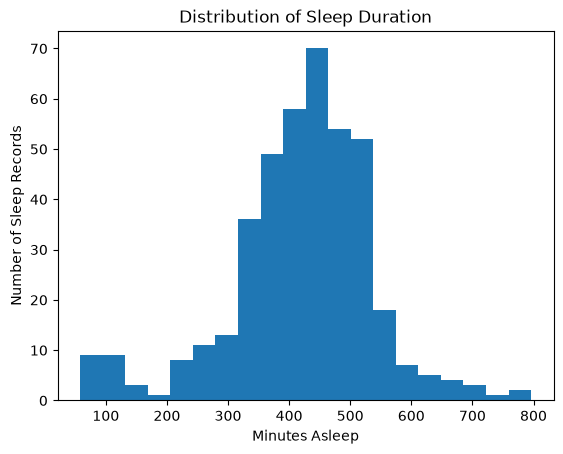

In [33]:

# Visualize the distribution of recorded sleep duration
import matplotlib.pyplot as plt

plt.hist(sleep_data["TotalMinutesAsleep"], bins=20)

plt.title("Distribution of Sleep Duration")
plt.xlabel("Minutes Asleep")
plt.ylabel("Number of Sleep Records")

plt.show()


In [34]:

# Find the shortest and longest recorded sleep durations
print("Minimum minutes asleep:",
      sleep_data["TotalMinutesAsleep"].min())

print("Maximum minutes asleep:",
      sleep_data["TotalMinutesAsleep"].max())


Minimum minutes asleep: 58
Maximum minutes asleep: 796


In [35]:

# Display the record with the shortest sleep duration
sleep_data.loc[
    sleep_data["TotalMinutesAsleep"].idxmin()
]


Id                              7007744171
SleepDay              5/1/2016 12:00:00 AM
TotalSleepRecords                        1
TotalMinutesAsleep                      58
TotalTimeInBed                          61
Name: 338, dtype: object

In [36]:

# Display the record with the longest sleep duration
sleep_data.loc[
    sleep_data["TotalMinutesAsleep"].idxmax()
]


Id                              1644430081
SleepDay              5/2/2016 12:00:00 AM
TotalSleepRecords                        1
TotalMinutesAsleep                     796
TotalTimeInBed                         961
Name: 27, dtype: object

In [37]:

# Count records where sleep time exceeds time in bed
invalid_sleep_records = (
    sleep_data["TotalMinutesAsleep"] >
    sleep_data["TotalTimeInBed"]
).sum()

print("Records with sleep time greater than time in bed:",
      invalid_sleep_records)


Records with sleep time greater than time in bed: 0


In [38]:

# Create a working copy of the original sleep dataset
sleep_clean = sleep_data.copy()

# Confirm the working copy was created
sleep_clean.shape


(413, 5)

In [39]:

# Remove exact duplicate sleep records
sleep_clean = sleep_clean.drop_duplicates()

# Verify the number of remaining records
sleep_clean.shape


(410, 5)

In [40]:

# Convert SleepDay to datetime in the cleaned dataset
sleep_clean["SleepDay"] = pd.to_datetime(
    sleep_clean["SleepDay"],
    format="%m/%d/%Y %I:%M:%S %p"
)

# Verify the new data type
sleep_clean["SleepDay"].dtype


dtype('<M8[us]')

In [41]:

# Check for duplicate participant-date combinations
duplicate_sleep_dates = sleep_clean.duplicated(
    subset=["Id", "SleepDay"]
).sum()

print("Duplicate participant-date records:", duplicate_sleep_dates)


Duplicate participant-date records: 0


In [42]:

# Check for missing values in each column
sleep_clean.isnull().sum()


Id                    0
SleepDay              0
TotalSleepRecords     0
TotalMinutesAsleep    0
TotalTimeInBed        0
dtype: int64

In [43]:

# Review the cleaned sleep dataset structure
sleep_clean.info()


<class 'pandas.DataFrame'>
Index: 410 entries, 0 to 412
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Id                  410 non-null    int64         
 1   SleepDay            410 non-null    datetime64[us]
 2   TotalSleepRecords   410 non-null    int64         
 3   TotalMinutesAsleep  410 non-null    int64         
 4   TotalTimeInBed      410 non-null    int64         
dtypes: datetime64[us](1), int64(4)
memory usage: 19.2 KB


In [44]:

# Create a working copy of the daily activity dataset
activity_clean = daily_activity.copy()

# Verify the working copy
activity_clean.shape


(940, 15)

In [45]:

# Convert ActivityDate to datetime
activity_clean["ActivityDate"] = pd.to_datetime(
    activity_clean["ActivityDate"],
    format="%m/%d/%Y"
)

# Verify the new data type
activity_clean["ActivityDate"].dtype


dtype('<M8[us]')

In [46]:

# Check for exact duplicate activity records
activity_clean.duplicated().sum()


np.int64(0)

In [47]:

# Check for duplicate participant-date combinations
duplicate_activity_dates = activity_clean.duplicated(
    subset=["Id", "ActivityDate"]
).sum()

print("Duplicate participant-date records:", duplicate_activity_dates)


Duplicate participant-date records: 0


In [48]:

# Check for missing values in each column
activity_clean.isnull().sum()


Id                          0
ActivityDate                0
TotalSteps                  0
TotalDistance               0
TrackerDistance             0
LoggedActivitiesDistance    0
VeryActiveDistance          0
ModeratelyActiveDistance    0
LightActiveDistance         0
SedentaryActiveDistance     0
VeryActiveMinutes           0
FairlyActiveMinutes         0
LightlyActiveMinutes        0
SedentaryMinutes            0
Calories                    0
dtype: int64

In [49]:

# Review the cleaned daily activity dataset
activity_clean.info()


<class 'pandas.DataFrame'>
RangeIndex: 940 entries, 0 to 939
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Id                        940 non-null    int64         
 1   ActivityDate              940 non-null    datetime64[us]
 2   TotalSteps                940 non-null    int64         
 3   TotalDistance             940 non-null    float64       
 4   TrackerDistance           940 non-null    float64       
 5   LoggedActivitiesDistance  940 non-null    float64       
 6   VeryActiveDistance        940 non-null    float64       
 7   ModeratelyActiveDistance  940 non-null    float64       
 8   LightActiveDistance       940 non-null    float64       
 9   SedentaryActiveDistance   940 non-null    float64       
 10  VeryActiveMinutes         940 non-null    int64         
 11  FairlyActiveMinutes       940 non-null    int64         
 12  LightlyActiveMinutes      940 non

In [50]:

# Find participants who appear in both datasets
common_participants = set(activity_clean["Id"]).intersection(
    set(sleep_clean["Id"])
)

# Count participants found in both datasets
len(common_participants)


24

In [51]:

# Count sleep records with matching activity dates
matching_records = sleep_clean.merge(
    activity_clean[["Id", "ActivityDate"]],
    left_on=["Id", "SleepDay"],
    right_on=["Id", "ActivityDate"],
    how="inner"
)

matching_records.shape


(410, 6)

In [52]:

# Combine activity and sleep data using participant ID and date
combined_data = activity_clean.merge(
    sleep_clean,
    left_on=["Id", "ActivityDate"],
    right_on=["Id", "SleepDay"],
    how="inner",
    validate="one_to_one"
)

# Check the dimensions of the combined dataset
combined_data.shape


(410, 19)

In [53]:

# Preview the first five rows of the merged dataset
combined_data.head()


,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories,SleepDay,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
0,1503960366,2016-04-12,13162,8.50,8.50,0.0,1.88,0.55,6.06,0.0,25,13,328,728,1985,2016-04-12,1,327,346
1,1503960366,2016-04-13,10735,6.97,6.97,0.0,1.57,0.69,4.71,0.0,21,19,217,776,1797,2016-04-13,2,384,407
2,1503960366,2016-04-15,9762,6.28,6.28,0.0,2.14,1.26,2.83,0.0,29,34,209,726,1745,2016-04-15,1,412,442
3,1503960366,2016-04-16,12669,8.16,8.16,0.0,2.71,0.41,5.04,0.0,36,10,221,773,1863,2016-04-16,2,340,367
4,1503960366,2016-04-17,9705,6.48,6.48,0.0,3.19,0.78,2.51,0.0,38,20,164,539,1728,2016-04-17,1,700,712


In [54]:

# Check for missing values in the merged dataset
combined_data.isnull().sum()


Id                          0
ActivityDate                0
TotalSteps                  0
TotalDistance               0
TrackerDistance             0
LoggedActivitiesDistance    0
VeryActiveDistance          0
ModeratelyActiveDistance    0
LightActiveDistance         0
SedentaryActiveDistance     0
VeryActiveMinutes           0
FairlyActiveMinutes         0
LightlyActiveMinutes        0
SedentaryMinutes            0
Calories                    0
SleepDay                    0
TotalSleepRecords           0
TotalMinutesAsleep          0
TotalTimeInBed              0
dtype: int64

In [55]:

# Check for duplicate participant-date combinations
combined_duplicates = combined_data.duplicated(
    subset=["Id", "ActivityDate"]
).sum()

print("Duplicate participant-date records:", combined_duplicates)


Duplicate participant-date records: 0


In [56]:

# Count unique participants in the merged dataset
combined_data["Id"].nunique()


24

## 3. Process - Data Cleaning and Preparation

I used Python and pandas to clean and prepare the Fitbit activity and sleep datasets for analysis.

I created separate working copies of both datasets so the original data would remain unchanged. I removed three duplicate records from the sleep dataset, reducing it from 413 to 410 records. I also converted the date columns in both datasets to datetime format.

After cleaning, I checked both datasets for missing values, duplicate records, and duplicate participant-date combinations. I confirmed that neither dataset contained missing values, duplicate records, or duplicate participant-date combinations.

Next, I compared participant IDs and dates to determine whether the datasets could be combined. All 24 participants in the sleep dataset were also represented in the activity dataset, and all 410 cleaned sleep records matched an activity record for the same participant and date.

I used an inner join to combine the datasets, resulting in 410 records and 19 columns.

### Data Limitations

The original activity dataset contains 33 participants, but only 24 have sleep records. The combined dataset therefore represents a smaller group of participants and only the dates when both activity and sleep data were available.

Some participants also have fewer recorded days than others. Missing sleep records do not necessarily mean participants did not sleep; they may reflect incomplete tracking.

The data was collected over approximately one month in 2016, so the findings may not reflect current fitness tracker habits or represent the broader population.

I will keep these limitations in mind when analyzing trends and developing marketing recommendations for Bellabeat.

## 4. Analyze - Daily Activity Patterns

In [57]:

# Summarize key daily activity measurements
activity_clean[
    [
        "TotalSteps",
        "VeryActiveMinutes",
        "FairlyActiveMinutes",
        "LightlyActiveMinutes",
        "SedentaryMinutes",
        "Calories"
    ]
].describe().round(2)


,TotalSteps,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
count,940.00,940.00,940.00,940.00,940.00,940.00
mean,7637.91,21.16,13.56,192.81,991.21,2303.61
std,5087.15,32.84,19.99,109.17,301.27,718.17
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,3789.75,0.00,0.00,127.00,729.75,1828.50
50%,7405.50,4.00,6.00,199.00,1057.50,2134.00
75%,10727.00,32.00,19.00,264.00,1229.50,2793.25
max,36019.00,210.00,143.00,518.00,1440.00,4900.00


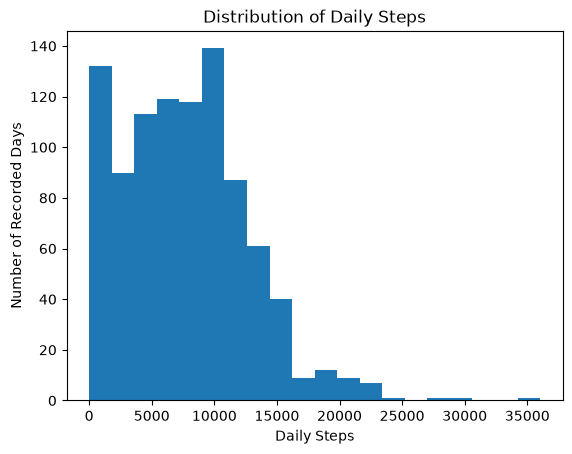

In [58]:

# Visualize the distribution of daily steps
plt.hist(activity_clean["TotalSteps"], bins=20)

plt.title("Distribution of Daily Steps")
plt.xlabel("Daily Steps")
plt.ylabel("Number of Recorded Days")

plt.show()


In [59]:

# Compare mean and median daily steps
print("Mean daily steps:",
      round(activity_clean["TotalSteps"].mean(), 2))

print("Median daily steps:",
      round(activity_clean["TotalSteps"].median(), 2))


Mean daily steps: 7637.91
Median daily steps: 7405.5


In [60]:

# Calculate the percentage of days with fewer than 5,000 steps
low_activity_days = (
    activity_clean["TotalSteps"] < 5000
).sum()

low_activity_percentage = (
    low_activity_days / len(activity_clean)
) * 100

print("Days with fewer than 5,000 steps:", low_activity_days)
print("Percentage of recorded days:",
      round(low_activity_percentage, 2))


Days with fewer than 5,000 steps: 303
Percentage of recorded days: 32.23


In [61]:

# Calculate the percentage of low-activity days with zero steps
zero_step_days = (activity_clean["TotalSteps"] == 0).sum()

zero_step_percentage = (
    zero_step_days / low_activity_days
) * 100

print("Zero-step days:", zero_step_days)
print("Percentage of low-activity days with zero steps:",
      round(zero_step_percentage, 2))


Zero-step days: 77
Percentage of low-activity days with zero steps: 25.41


In [62]:

# Compare average daily steps with and without zero-step days

average_all_days = activity_clean["TotalSteps"].mean()

average_nonzero_days = activity_clean.loc[
    activity_clean["TotalSteps"] > 0,
    "TotalSteps"
].mean()

print("Average steps (all days):",
      round(average_all_days, 2))

print("Average steps (excluding zero-step days):",
      round(average_nonzero_days, 2))


Average steps (all days): 7637.91
Average steps (excluding zero-step days): 8319.39


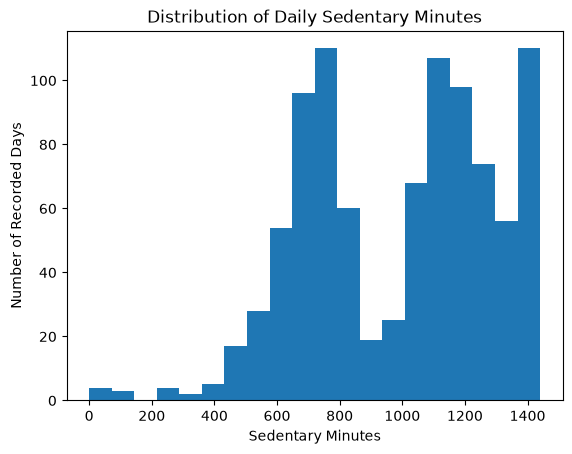

In [63]:

# Examine the distribution of daily sedentary minutes
plt.hist(
    activity_clean["SedentaryMinutes"],
    bins=20
)

plt.title("Distribution of Daily Sedentary Minutes")
plt.xlabel("Sedentary Minutes")
plt.ylabel("Number of Recorded Days")

plt.show()


In [64]:

# Compare mean and median daily sedentary minutes

print("Mean sedentary minutes:",
      round(activity_clean["SedentaryMinutes"].mean(), 2))

print("Median sedentary minutes:",
      round(activity_clean["SedentaryMinutes"].median(), 2))


Mean sedentary minutes: 991.21
Median sedentary minutes: 1057.5


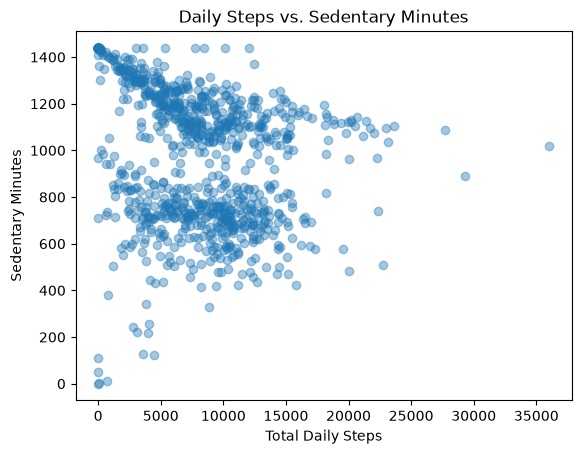

In [65]:

# Explore the relationship between daily steps and sedentary time

plt.scatter(
    activity_clean["TotalSteps"],
    activity_clean["SedentaryMinutes"],
    alpha=0.4
)

plt.title("Daily Steps vs. Sedentary Minutes")
plt.xlabel("Total Daily Steps")
plt.ylabel("Sedentary Minutes")

plt.show()


In [66]:

# Calculate correlation between daily steps and sedentary minutes

correlation = activity_clean[
    "TotalSteps"
].corr(activity_clean["SedentaryMinutes"])

print("Correlation:", round(correlation, 3))


Correlation: -0.327


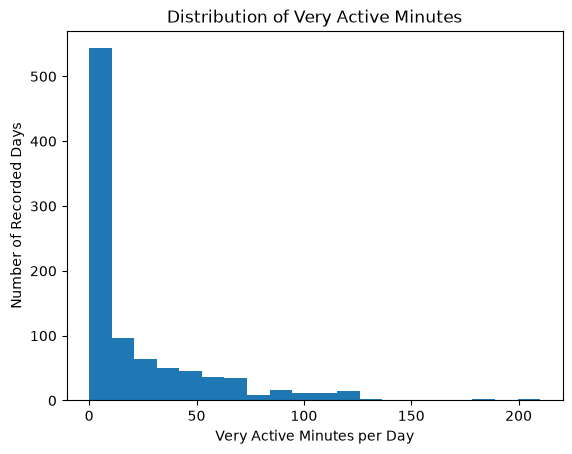

In [67]:

# Visualize the distribution of very active minutes

plt.hist(
    activity_clean["VeryActiveMinutes"],
    bins=20
)

plt.title("Distribution of Very Active Minutes")
plt.xlabel("Very Active Minutes per Day")
plt.ylabel("Number of Recorded Days")

plt.show()


In [68]:

# Compare mean and median very active minutes

print("Mean very active minutes:",
      round(activity_clean["VeryActiveMinutes"].mean(), 2))

print("Median very active minutes:",
      round(activity_clean["VeryActiveMinutes"].median(), 2))


Mean very active minutes: 21.16
Median very active minutes: 4.0


In [69]:

# Count days with zero very active minutes

zero_active_days = (
    activity_clean["VeryActiveMinutes"] == 0
).sum()

zero_active_percentage = (
    zero_active_days / len(activity_clean)
) * 100

print("Days with zero very active minutes:",
      zero_active_days)

print("Percentage of recorded days:",
      round(zero_active_percentage, 2))


Days with zero very active minutes: 409
Percentage of recorded days: 43.51


In [70]:

# Summarize daily light activity

print("Mean lightly active minutes:",
      round(activity_clean["LightlyActiveMinutes"].mean(), 2))

print("Median lightly active minutes:",
      round(activity_clean["LightlyActiveMinutes"].median(), 2))


Mean lightly active minutes: 192.81
Median lightly active minutes: 199.0


In [71]:

# Compare median minutes across activity categories

activity_columns = [
    "VeryActiveMinutes",
    "FairlyActiveMinutes",
    "LightlyActiveMinutes",
    "SedentaryMinutes"
]

activity_clean[activity_columns].median()


VeryActiveMinutes          4.0
FairlyActiveMinutes        6.0
LightlyActiveMinutes     199.0
SedentaryMinutes        1057.5
dtype: float64

In [72]:

# Calculate average and median sleep duration in hours

print("Mean sleep duration (hours):",
      round(sleep_clean["TotalMinutesAsleep"].mean() / 60, 2))

print("Median sleep duration (hours):",
      round(sleep_clean["TotalMinutesAsleep"].median() / 60, 2))


Mean sleep duration (hours): 6.99
Median sleep duration (hours): 7.21


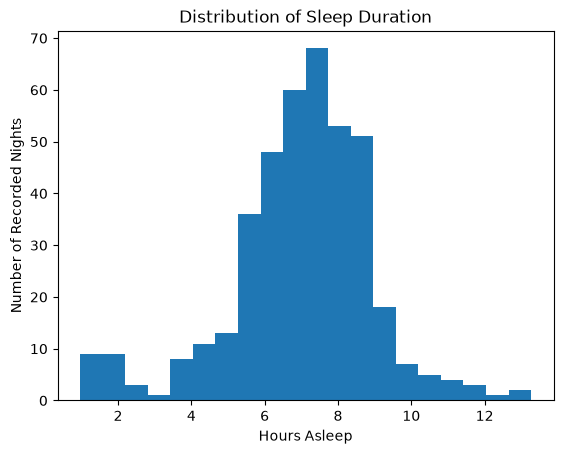

In [73]:

# Visualize the distribution of sleep duration in hours

plt.hist(
    sleep_clean["TotalMinutesAsleep"] / 60,
    bins=20
)

plt.title("Distribution of Sleep Duration")
plt.xlabel("Hours Asleep")
plt.ylabel("Number of Recorded Nights")

plt.show()


In [74]:

# Calculate nights with fewer than 7 hours of sleep

short_sleep_nights = (
    sleep_clean["TotalMinutesAsleep"] < 420
).sum()

short_sleep_percentage = (
    short_sleep_nights / len(sleep_clean)
) * 100

print("Nights with fewer than 7 hours of sleep:",
      short_sleep_nights)

print("Percentage of recorded nights:",
      round(short_sleep_percentage, 2))


Nights with fewer than 7 hours of sleep: 181
Percentage of recorded nights: 44.15


In [75]:

# Calculate sleep efficiency for each recorded night

sleep_clean["SleepEfficiency"] = (
    sleep_clean["TotalMinutesAsleep"] /
    sleep_clean["TotalTimeInBed"]
) * 100

print("Mean sleep efficiency:",
      round(sleep_clean["SleepEfficiency"].mean(), 2))

print("Median sleep efficiency:",
      round(sleep_clean["SleepEfficiency"].median(), 2))


Mean sleep efficiency: 91.65
Median sleep efficiency: 94.26


In [76]:

# Calculate nights with sleep efficiency below 85%

low_efficiency_nights = (
    sleep_clean["SleepEfficiency"] < 85
).sum()

low_efficiency_percentage = (
    low_efficiency_nights / len(sleep_clean)
) * 100

print("Nights with sleep efficiency below 85%:",
      low_efficiency_nights)

print("Percentage of recorded nights:",
      round(low_efficiency_percentage, 2))


Nights with sleep efficiency below 85%: 33
Percentage of recorded nights: 8.05


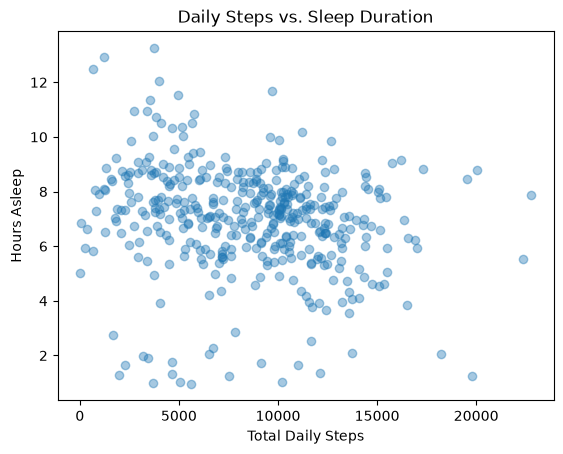

In [77]:

# Explore the relationship between daily steps and sleep duration

plt.scatter(
    combined_data["TotalSteps"],
    combined_data["TotalMinutesAsleep"] / 60,
    alpha=0.4
)

plt.title("Daily Steps vs. Sleep Duration")
plt.xlabel("Total Daily Steps")
plt.ylabel("Hours Asleep")

plt.show()


In [78]:

# Calculate correlation between daily steps and sleep duration

sleep_steps_correlation = combined_data[
    "TotalSteps"
].corr(combined_data["TotalMinutesAsleep"])

print("Steps vs. sleep correlation:",
      round(sleep_steps_correlation, 3))


Steps vs. sleep correlation: -0.19


In [79]:

# Calculate correlation between vigorous activity and sleep duration

active_sleep_correlation = combined_data[
    "VeryActiveMinutes"
].corr(combined_data["TotalMinutesAsleep"])

print("Very active minutes vs. sleep correlation:",
      round(active_sleep_correlation, 3))


Very active minutes vs. sleep correlation: -0.088


In [80]:

# Calculate correlation between light activity and sleep duration

light_sleep_correlation = combined_data[
    "LightlyActiveMinutes"
].corr(combined_data["TotalMinutesAsleep"])

print("Light activity vs. sleep correlation:",
      round(light_sleep_correlation, 3))


Light activity vs. sleep correlation: 0.028


In [81]:

# Calculate correlation between sedentary time and sleep duration

sedentary_sleep_correlation = combined_data[
    "SedentaryMinutes"
].corr(combined_data["TotalMinutesAsleep"])

print("Sedentary time vs. sleep correlation:",
      round(sedentary_sleep_correlation, 3))


Sedentary time vs. sleep correlation: -0.601


In [82]:

# Examine combined sedentary and sleep time

combined_data["SedentaryPlusSleep"] = (
    combined_data["SedentaryMinutes"] +
    combined_data["TotalMinutesAsleep"]
)

print(
    combined_data["SedentaryPlusSleep"].describe()
)


count     410.000000
mean     1131.273171
std       134.126600
min       302.000000
25%      1072.000000
50%      1143.000000
75%      1207.000000
max      1490.000000
Name: SedentaryPlusSleep, dtype: float64


In [83]:

# Check whether recorded activity and sleep time exceed 24 hours

total_recorded_minutes = (
    combined_data["SedentaryMinutes"]
    + combined_data["LightlyActiveMinutes"]
    + combined_data["FairlyActiveMinutes"]
    + combined_data["VeryActiveMinutes"]
    + combined_data["TotalMinutesAsleep"]
)

days_over_24_hours = (total_recorded_minutes > 1440).sum()

print("Records exceeding 24 hours:", days_over_24_hours)
print("Maximum combined minutes:", total_recorded_minutes.max())


Records exceeding 24 hours: 90
Maximum combined minutes: 1635


In [84]:

# Check whether activity categories alone exceed 24 hours

activity_minutes = (
    combined_data["SedentaryMinutes"]
    + combined_data["LightlyActiveMinutes"]
    + combined_data["FairlyActiveMinutes"]
    + combined_data["VeryActiveMinutes"]
)

print("Activity records exceeding 24 hours:",
      (activity_minutes > 1440).sum())

print("Maximum activity minutes:",
      activity_minutes.max())


Activity records exceeding 24 hours: 0
Maximum activity minutes: 1398


In [85]:

# Summarize total activity minutes per matched day

activity_minutes.describe()


count     410.000000
mean      971.612195
std       167.523522
min         2.000000
25%       906.250000
50%       983.000000
75%      1042.000000
max      1398.000000
dtype: float64

In [86]:

# Compare sleep duration by time-budget status

combined_data["Over24Hours"] = total_recorded_minutes > 1440

print(
    combined_data.groupby("Over24Hours")[
        "TotalMinutesAsleep"
    ].mean().div(60).round(2)
)


Over24Hours
False    6.77
True     7.76
Name: TotalMinutesAsleep, dtype: float64


### Activity and Sleep Data Limitations

While analyzing the relationship between physical activity and sleep, I found a moderately strong negative correlation (-0.601) between sedentary minutes and sleep duration. However, I wanted to investigate this relationship further before drawing conclusions.

When I added the activity categories together, none of the 410 matched records exceeded 24 hours. After including sleep duration, 90 records (approximately 22%) exceeded 24 hours, with the highest total reaching 1,635 minutes.

I also found that records exceeding 24 hours averaged approximately 8 hours of sleep, compared with 7 hours for records that stayed within the limit.

These findings suggest that the activity and sleep measurements may overlap or use different reporting periods. Because of this limitation, I would be cautious about using the sedentary-time correlation to make recommendations about improving sleep.

This reinforced the importance of checking the data and understanding its limitations before making business recommendations.

In [87]:

# Calculate average daily steps for each participant

participant_steps = (
    activity_clean.groupby("Id")["TotalSteps"]
    .mean()
    .sort_values()
)

print(participant_steps)


Id
1927972279      916.129032
8792009665     1853.724138
4020332650     2267.225806
6775888955     2519.692308
1844505072     2580.064516
4057192912     3838.000000
2320127002     4716.870968
4445114986     4796.548387
2026352035     5566.870968
6290855005     5649.551724
1624580081     5743.903226
8253242879     6482.157895
3372868164     6861.650000
6117666160     7046.714286
8583815059     7198.516129
4319703577     7268.838710
1644430081     7282.966667
2873212765     7555.774194
4558609924     7685.129032
5577150313     8304.433333
4702921684     8572.064516
5553957443     8612.580645
8378563200     8717.709677
7086361926     9371.774194
2347167796     9519.666667
6962181067     9794.806452
4388161847    10813.935484
3977333714    10984.566667
7007744171    11323.423077
2022484408    11370.645161
1503960366    12116.741935
8053475328    14763.290323
8877689391    16040.032258
Name: TotalSteps, dtype: float64


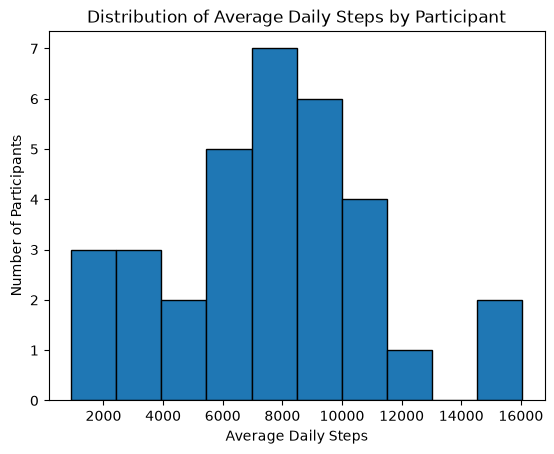

In [88]:

# Visualize average daily steps by participant

plt.hist(
    participant_steps,
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Average Daily Steps by Participant")
plt.xlabel("Average Daily Steps")
plt.ylabel("Number of Participants")

plt.show()


In [89]:

# Group participants by their average daily step counts

participant_activity_groups = pd.cut(
    participant_steps,
    bins=[-1, 4999, 9999, float("inf")],
    labels=["Lower Activity", "Moderate Activity", "Higher Activity"]
)

print(participant_activity_groups.value_counts().sort_index())


TotalSteps
Lower Activity        8
Moderate Activity    18
Higher Activity       7
Name: count, dtype: int64


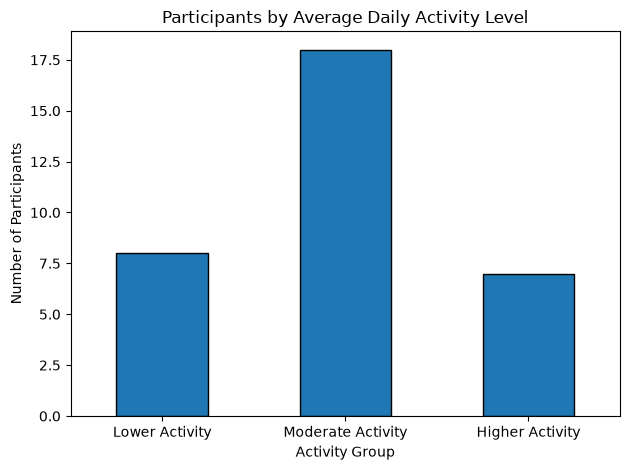

In [90]:

# Visualize participant activity groups

activity_group_counts = (
    participant_activity_groups
    .value_counts()
    .sort_index()
)

activity_group_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Participants by Average Daily Activity Level")
plt.xlabel("Activity Group")
plt.ylabel("Number of Participants")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()


In [91]:

# Add participant activity groups to matched sleep records

combined_data["ActivityGroup"] = combined_data["Id"].map(
    participant_activity_groups
)

print(combined_data["ActivityGroup"].value_counts())


ActivityGroup
Moderate Activity    266
Higher Activity       81
Lower Activity        63
Name: count, dtype: int64


In [92]:

# Count unique participants with sleep data in each activity group

sleep_participants_by_group = (
    combined_data.groupby(
        "ActivityGroup",
        observed=True
    )["Id"].nunique()
)

print(sleep_participants_by_group)


ActivityGroup
Lower Activity        7
Moderate Activity    12
Higher Activity       5
Name: Id, dtype: int64


In [93]:

# Check sleep record counts for each participant

participant_sleep_counts = (
    combined_data.groupby(["Id", "ActivityGroup"], observed=True)
    .size()
    .sort_values(ascending=False)
)

print(participant_sleep_counts)


Id          ActivityGroup    
8378563200  Moderate Activity    31
6962181067  Moderate Activity    31
5553957443  Moderate Activity    31
2026352035  Moderate Activity    28
3977333714  Higher Activity      28
4445114986  Lower Activity       28
4702921684  Moderate Activity    27
5577150313  Moderate Activity    26
4319703577  Moderate Activity    26
1503960366  Higher Activity      25
7086361926  Moderate Activity    24
4388161847  Higher Activity      23
6117666160  Moderate Activity    18
8792009665  Lower Activity       15
2347167796  Moderate Activity    15
4020332650  Lower Activity        8
1927972279  Lower Activity        5
4558609924  Moderate Activity     5
1644430081  Moderate Activity     4
6775888955  Lower Activity        3
8053475328  Higher Activity       3
1844505072  Lower Activity        3
7007744171  Higher Activity       2
2320127002  Lower Activity        1
dtype: int64


In [94]:

# Verify participant and sleep record counts together

group_check = (
    combined_data.groupby("ActivityGroup", observed=True)
    .agg(
        UniqueParticipants=("Id", "nunique"),
        SleepRecords=("Id", "size")
    )
)

print(group_check)


                   UniqueParticipants  SleepRecords
ActivityGroup                                      
Lower Activity                      7            63
Moderate Activity                  12           266
Higher Activity                     5            81


In [95]:

# Compare average sleep duration by activity group
# Give each participant equal weight

participant_sleep = (
    combined_data.groupby(
        ["Id", "ActivityGroup"],
        observed=True
    )["TotalMinutesAsleep"]
    .mean()
    .reset_index()
)

average_sleep_by_group = (
    participant_sleep.groupby(
        "ActivityGroup",
        observed=True
    )["TotalMinutesAsleep"]
    .mean()
    .div(60)
    .round(2)
)

print(average_sleep_by_group)


ActivityGroup
Lower Activity       6.31
Moderate Activity    6.93
Higher Activity      4.73
Name: TotalMinutesAsleep, dtype: float64


In [96]:

# Examine variation in participant average sleep duration

sleep_variation = (
    participant_sleep.groupby(
        "ActivityGroup",
        observed=True
    )["TotalMinutesAsleep"]
    .agg(["count", "min", "median", "max"])
    .div(60)
    .round(2)
)

# Restore participant counts to whole numbers
sleep_variation["count"] = (
    participant_sleep.groupby(
        "ActivityGroup",
        observed=True
    )["Id"].nunique()
)

print(sleep_variation)


                   count   min  median    max
ActivityGroup                                
Lower Activity         7  1.02    6.42  10.87
Moderate Activity     12  2.13    7.46   8.44
Higher Activity        5  1.14    4.95   6.67


In [97]:

# Identify participants averaging under 4 hours of recorded sleep

short_sleep_participants = participant_sleep[
    participant_sleep["TotalMinutesAsleep"] < 240
].copy()

short_sleep_participants["AverageSleepHours"] = (
    short_sleep_participants["TotalMinutesAsleep"] / 60
).round(2)

print(
    short_sleep_participants[
        ["Id", "ActivityGroup", "AverageSleepHours"]
    ].sort_values("AverageSleepHours")
)


            Id      ActivityGroup  AverageSleepHours
5   2320127002     Lower Activity               1.02
19  7007744171    Higher Activity               1.14
12  4558609924  Moderate Activity               2.13


In [98]:

# Check sleep record counts for participants
# with unusually low average sleep duration

short_sleep_record_counts = (
    combined_data[
        combined_data["Id"].isin(
            short_sleep_participants["Id"]
        )
    ]
    .groupby("Id")
    .agg(
        RecordedNights=("TotalMinutesAsleep", "count"),
        MinimumSleep=("TotalMinutesAsleep", "min"),
        MaximumSleep=("TotalMinutesAsleep", "max")
    )
)

# Convert sleep duration from minutes to hours
short_sleep_record_counts[
    ["MinimumSleep", "MaximumSleep"]
] = (
    short_sleep_record_counts[
        ["MinimumSleep", "MaximumSleep"]
    ] / 60
).round(2)

print(short_sleep_record_counts)


            RecordedNights  MinimumSleep  MaximumSleep
Id                                                    
2320127002               1          1.02          1.02
4558609924               5          1.72          2.85
7007744171               2          0.97          1.32


In [99]:

# Sensitivity analysis:
# Compare sleep averages excluding participants
# who averaged fewer than 4 hours of recorded sleep

sleep_sensitivity = (
    participant_sleep[
        participant_sleep["TotalMinutesAsleep"] >= 240
    ]
    .groupby("ActivityGroup", observed=True)
    .agg(
        Participants=("Id", "nunique"),
        AverageSleepMinutes=("TotalMinutesAsleep", "mean")
    )
)

sleep_sensitivity["AverageSleepHours"] = (
    sleep_sensitivity["AverageSleepMinutes"] / 60
).round(2)

print(
    sleep_sensitivity[
        ["Participants", "AverageSleepHours"]
    ]
)


                   Participants  AverageSleepHours
ActivityGroup                                     
Lower Activity                6               7.19
Moderate Activity            11               7.37
Higher Activity               4               5.63


In [100]:

# Calculate exact original participant-weighted sleep averages

original_sleep_averages = (
    participant_sleep.groupby(
        "ActivityGroup",
        observed=True
    )["TotalMinutesAsleep"]
    .mean()
    .div(60)
    .round(2)
)

print(original_sleep_averages)


ActivityGroup
Lower Activity       6.31
Moderate Activity    6.93
Higher Activity      4.73
Name: TotalMinutesAsleep, dtype: float64


### Activity Levels and Sleep Duration: Key Findings

I compared average recorded sleep duration across three participant activity groups: lower, moderate, and higher activity.

Initially, the moderate-activity group averaged 6.93 hours of sleep, compared with 6.31 hours for the lower-activity group and 4.73 hours for the higher-activity group.

During my analysis, I identified three participants with unusually short average recorded sleep durations. These participants had only one, two, or five recorded nights, raising questions about how representative their sleep data was.

To understand how much these observations affected my findings, I performed a sensitivity analysis excluding those three participants. The adjusted averages increased to 7.19 hours for lower activity, 7.37 hours for moderate activity, and 5.63 hours for higher activity.

The moderate-activity group continued to have the highest average recorded sleep duration, while the higher-activity group had the lowest. However, the higher-activity group contained only four participants after the sensitivity analysis.

**Key takeaway:** My findings suggest that sleep patterns may differ across activity levels, but the small sample sizes and limited sleep records mean I cannot draw firm conclusions. For Bellabeat, this supports exploring marketing strategies that encourage users to track both physical activity and sleep as part of their overall wellness routines.

*Note: The sensitivity analysis was used to test the stability of the findings. The original records were retained.*

In [101]:

# Examine daily step consistency for each participant

participant_step_consistency = (
    activity_clean.groupby("Id")["TotalSteps"]
    .agg(["count", "mean", "std"])
    .round(2)
)

print(participant_step_consistency.head(10))


            count      mean      std
Id                                  
1503960366     31  12116.74  3052.48
1624580081     31   5743.90  6177.05
1644430081     30   7282.97  4325.48
1844505072     31   2580.06  2712.84
1927972279     31    916.13  1205.27
2022484408     31  11370.65  2806.99
2026352035     31   5566.87  2977.83
2320127002     31   4716.87  2254.61
2347167796     18   9519.67  4682.09
2873212765     31   7555.77  1514.47


In [102]:

# Calculate relative variation in daily steps

participant_step_consistency["CV_Percent"] = (
    participant_step_consistency["std"]
    / participant_step_consistency["mean"]
    * 100
).round(2)

print(
    participant_step_consistency[
        ["mean", "std", "CV_Percent"]
    ].head(10)
)


                mean      std  CV_Percent
Id                                       
1503960366  12116.74  3052.48       25.19
1624580081   5743.90  6177.05      107.54
1644430081   7282.97  4325.48       59.39
1844505072   2580.06  2712.84      105.15
1927972279    916.13  1205.27      131.56
2022484408  11370.65  2806.99       24.69
2026352035   5566.87  2977.83       53.49
2320127002   4716.87  2254.61       47.80
2347167796   9519.67  4682.09       49.18
2873212765   7555.77  1514.47       20.04


In [103]:

# Summarize activity consistency across all participants

print(
    participant_step_consistency["CV_Percent"].describe()
)


count     33.000000
mean      57.620303
std       34.038534
min       20.040000
25%       36.850000
50%       47.260000
75%       59.390000
max      148.630000
Name: CV_Percent, dtype: float64


In [104]:

# Count zero-step days for each participant

zero_step_counts = (
    activity_clean.groupby("Id")["TotalSteps"]
    .apply(lambda steps: (steps == 0).sum())
    .sort_values(ascending=False)
)

print(zero_step_counts.head(10))


Id
4020332650    14
1927972279    14
8792009665    10
1844505072    10
6775888955     9
6117666160     5
6290855005     5
5577150313     2
7007744171     2
1503960366     1
Name: TotalSteps, dtype: int64


In [105]:

# Recalculate step consistency excluding zero-step days

nonzero_step_consistency = (
    activity_clean[
        activity_clean["TotalSteps"] > 0
    ]
    .groupby("Id")["TotalSteps"]
    .agg(["count", "mean", "std"])
)

nonzero_step_consistency["CV_Percent"] = (
    nonzero_step_consistency["std"]
    / nonzero_step_consistency["mean"]
    * 100
)

print(
    nonzero_step_consistency["CV_Percent"]
    .describe()
    .round(2)
)


count     33.00
mean      45.32
std       21.27
min       16.77
25%       31.19
50%       40.38
75%       53.49
max      107.54
Name: CV_Percent, dtype: float64


In [106]:

# Compare zero-step days with original activity variability

consistency_zero_check = pd.DataFrame({
    "ZeroStepDays": zero_step_counts,
    "OriginalCV": participant_step_consistency["CV_Percent"]
})

print(
    consistency_zero_check.corr().round(3)
)


              ZeroStepDays  OriginalCV
ZeroStepDays         1.000       0.865
OriginalCV           0.865       1.000


### Daily Activity Consistency: Key Findings

I examined how consistently participants recorded daily steps by calculating the coefficient of variation (CV) for each participant.

The median CV across all 33 participants was 47.26%, indicating considerable variation in daily step counts relative to participants' averages.

I also found that 77 activity records contained zero steps. Five participants accounted for 57 of those records, or approximately 74%.

To investigate how these records affected activity consistency, I recalculated CV values after excluding zero-step days. The median CV decreased from 47.26% to 40.38%, while the mean decreased from 57.62% to 45.32%.

I also found a strong positive correlation (r = 0.865) between participants' zero-step day counts and their original CV values. However, because zero-step days directly influence the CV calculation, this correlation should not be interpreted as evidence of a causal relationship.

**Key takeaway:** Participants demonstrated different levels of consistency in their recorded daily activity. Although zero-step days contributed to this variation, differences remained after those records were excluded.

**Potential Bellabeat opportunity:** Bellabeat could explore marketing messages that emphasize realistic daily goals, consistency, and long-term progress rather than focusing exclusively on achieving high step counts.

**Limitations:** Zero-step days may represent inactivity, incomplete device wear, or missing tracking. The analysis cannot distinguish between these explanations, and the dataset does not establish users' preferences for particular wellness features.

*Note: Excluding zero-step days was a sensitivity analysis. The original activity records were retained.*

In [107]:

# Count participants with high daily step variability
# after excluding zero-step days

high_variability_count = (
    nonzero_step_consistency["CV_Percent"] > 50
).sum()

print("Participants with CV above 50%:", high_variability_count)
print("Total participants:", len(nonzero_step_consistency))


Participants with CV above 50%: 9
Total participants: 33


After excluding zero-step days, I found that 9 of the 33 participants (27.3%) had a coefficient of variation above 50%. This indicates that a meaningful minority of participants still showed relatively high variation in recorded daily steps. However, the 50% threshold was chosen for exploratory purposes and does not represent an established fitness classification. These findings suggest that Bellabeat could explore personalized activity goals and habit-building messages, while recognizing that activity consistency varies across users.

### Analyze Phase Summary

During the Analyze phase, I examined Fitbit activity and sleep data to identify patterns that could help Bellabeat better understand wellness-tracking behaviors and explore potential marketing opportunities for the Bellabeat Leaf.

**Physical Activity**

The average number of daily steps was approximately 7,638, and about 32% of recorded days had fewer than 5,000 steps. When I grouped participants by their average daily steps, I found that 18 of the 33 participants fell into the moderate-activity group.

These findings suggest that realistic activity goals and personalized progress tracking could be useful areas for Bellabeat to explore.

**Activity Consistency**

I also examined how much participants' daily step counts varied. After excluding zero-step days for a sensitivity analysis, I measured how much each participant's daily step counts varied relative to their average. Using the coefficient of variation (CV), I found that 9 of the 33 participants (27.3%) had a CV above 50%, indicating relatively high day-to-day variation based on the threshold I selected for this analysis.

This suggests that some participants may benefit from wellness messaging focused on building consistent routines rather than achieving high step counts every day.

**Sleep Patterns**

Approximately 44% of recorded nights had fewer than seven hours of sleep. Average recorded sleep efficiency was approximately 92%.

When I compared sleep duration across activity groups, I found differences in average recorded sleep. However, these results were sensitive to participants with unusually short sleep records, and the groups were relatively small.

These findings suggest that sleep awareness could be another useful area for Bellabeat's marketing strategy.

**Data Limitations**

The dataset contains a small sample of Fitbit users and covers approximately one month in 2016. Not every participant contributed sleep data, and some records may reflect incomplete device tracking.

I also identified potential inconsistencies between activity and sleep recording periods. Because of these limitations, the findings should be treated as exploratory rather than representative of all wellness-tracker users.

**Overall Takeaway**

My analysis identified three potential opportunities for Bellabeat:

1. Encourage achievable and personalized daily activity goals.
2. Promote consistent wellness habits and long-term progress.
3. Highlight sleep tracking and awareness as part of a balanced wellness routine.

These opportunities will guide the recommendations I develop during the Share and Act phases. They are hypotheses informed by the Fitbit data, rather than proven customer preferences or marketing outcomes.

## 5. Share - Communicating My Findings

In this phase, I will present the most important findings from my analysis of Fitbit activity and sleep data.

My goal is to communicate the results in a way that is clear, easy to understand, and useful for Bellabeat's marketing team.

I will use visualizations to highlight patterns in daily activity, activity consistency, and sleep behaviors. I will also explain the limitations of the data so that my findings are not overstated.

These insights will help guide my final marketing recommendations for the Bellabeat Leaf.

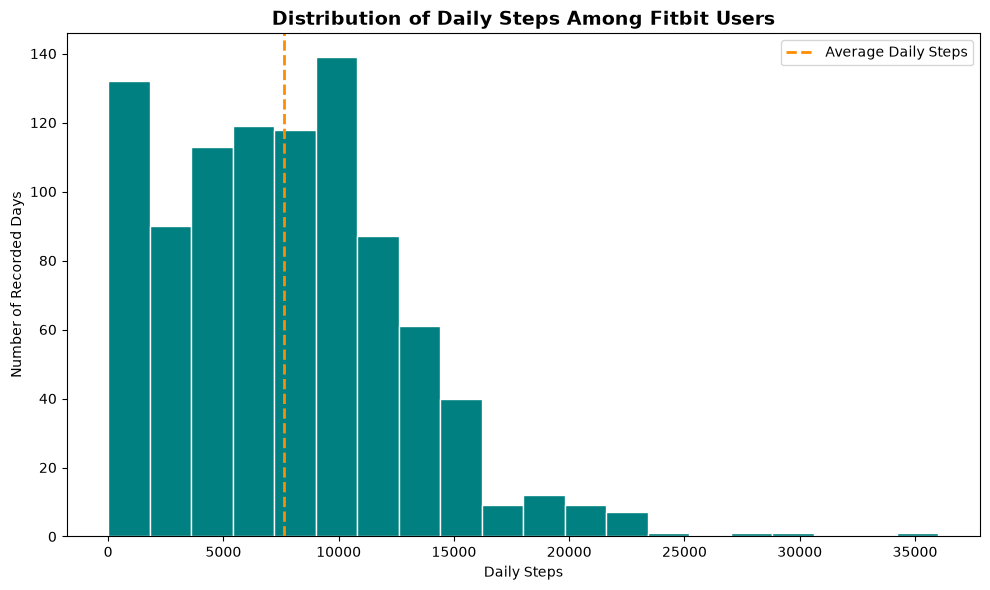

In [108]:

# Share Visualization 1: Distribution of Daily Steps

plt.figure(figsize=(10, 6))

plt.hist(
    activity_clean["TotalSteps"],
    bins=20,
    color="teal",
    edgecolor="white"
)

plt.axvline(
    activity_clean["TotalSteps"].mean(),
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label="Average Daily Steps"
)

plt.title(
    "Distribution of Daily Steps Among Fitbit Users",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Daily Steps")
plt.ylabel("Number of Recorded Days")

plt.legend()
plt.tight_layout()
plt.show()


### Visualization 1: Distribution of Daily Steps

This histogram shows the distribution of daily step counts across 940 Fitbit activity records.

The average was approximately 7,638 steps per day, represented by the orange dashed line. However, daily activity levels varied, and approximately 32% of recorded days had fewer than 5,000 steps.

This suggests that participants had different activity patterns and that reaching high daily step totals may not have been a consistent behavior across the sample.

**Marketing insight:** Bellabeat could explore promoting realistic, personalized activity goals that encourage gradual progress rather than focusing only on reaching a specific step count.

**Limitation:** Each observation represents a recorded day rather than a unique participant. Some zero-step records may reflect incomplete device tracking, and the findings cannot be generalized to all Bellabeat customers.

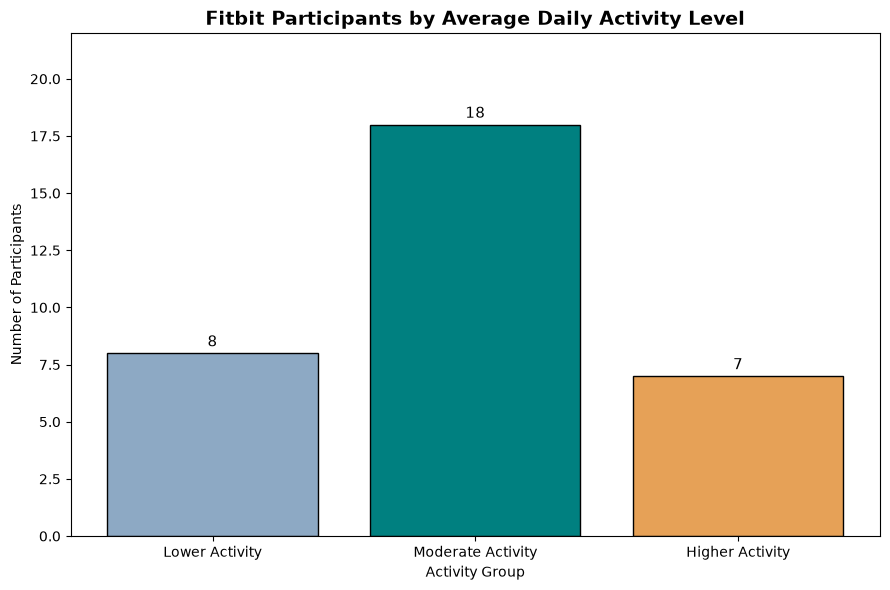

In [109]:

# Share Visualization 2: Participant Activity Groups

activity_group_counts = (
    participant_activity_groups
    .value_counts()
    .reindex([
        "Lower Activity",
        "Moderate Activity",
        "Higher Activity"
    ])
)

plt.figure(figsize=(9, 6))

bars = plt.bar(
    activity_group_counts.index,
    activity_group_counts.values,
    color=["#8DA9C4", "#008080", "#E6A157"],
    edgecolor="black"
)

plt.title(
    "Fitbit Participants by Average Daily Activity Level",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Activity Group")
plt.ylabel("Number of Participants")
plt.ylim(0, activity_group_counts.max() + 4)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        str(int(bar.get_height())),
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()


### Visualization 2: Participant Activity Levels

This bar chart shows how the 33 Fitbit participants were grouped based on their average recorded daily steps.

The largest group was Moderate Activity, with 18 participants (54.5%). The Lower Activity group included 8 participants (24.2%), while the Higher Activity group included 7 participants (21.2%).

These results show that participants had different activity levels, with more than half falling into the moderate-activity category.

**Marketing insight:** Bellabeat could explore personalized activity goals and messaging for users with different activity levels. For example, users with lower recorded activity might benefit from encouragement to build manageable daily habits, while more active users might respond to progress tracking and goal-setting features.

**Limitation:** These groups were created using exploratory step-count thresholds and do not represent established fitness classifications. The sample is small, and recorded step counts may be affected by incomplete device tracking.

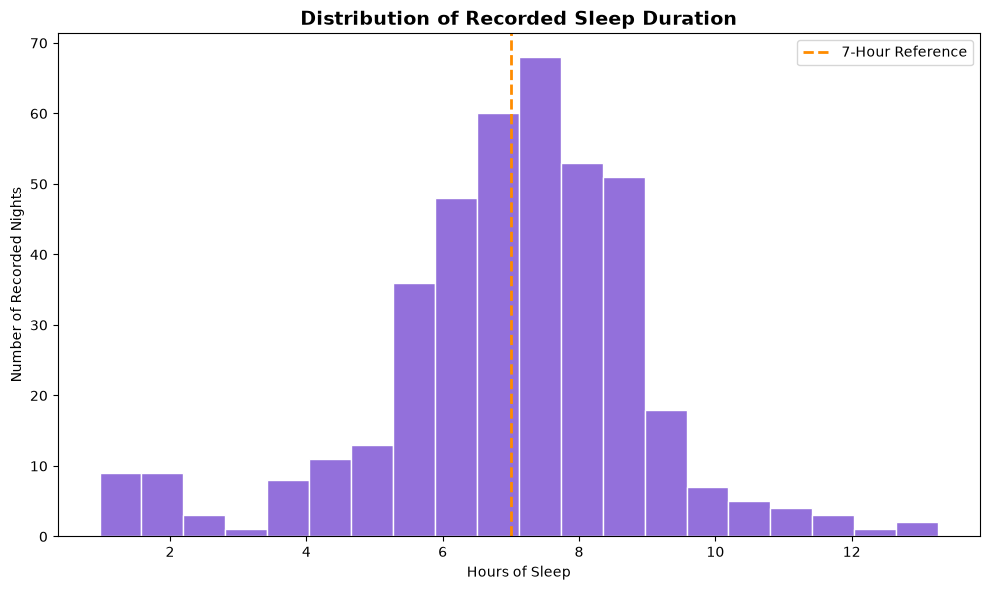

In [110]:

# Share Visualization 3: Distribution of Sleep Duration

sleep_hours = sleep_clean["TotalMinutesAsleep"] / 60

plt.figure(figsize=(10, 6))

plt.hist(
    sleep_hours,
    bins=20,
    color="mediumpurple",
    edgecolor="white"
)

plt.axvline(
    7,
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label="7-Hour Reference"
)

plt.title(
    "Distribution of Recorded Sleep Duration",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Hours of Sleep")
plt.ylabel("Number of Recorded Nights")

plt.legend()
plt.tight_layout()
plt.show()


### Visualization 3: Distribution of Sleep Duration

This histogram shows the distribution of recorded sleep duration across 410 sleep records from 24 Fitbit participants.

Average recorded sleep duration was approximately seven hours. However, 181 of the 410 recorded nights (44.1%) had fewer than seven hours of sleep.

The orange dashed line represents the seven-hour reference point and helps illustrate how frequently participants recorded shorter sleep durations.

**Marketing insight:** Bellabeat could explore highlighting sleep tracking and awareness as part of its wellness messaging. Features such as sleep summaries, personalized insights, and reminders to maintain consistent bedtime routines could help users become more aware of their sleep patterns.

**Limitation:** The dataset contains recorded sleep information rather than a complete history of each participant's sleep. Some participants contributed more records than others, and incomplete device tracking may affect the results. These findings do not establish that participants had sleep problems or that specific features would improve their sleep.

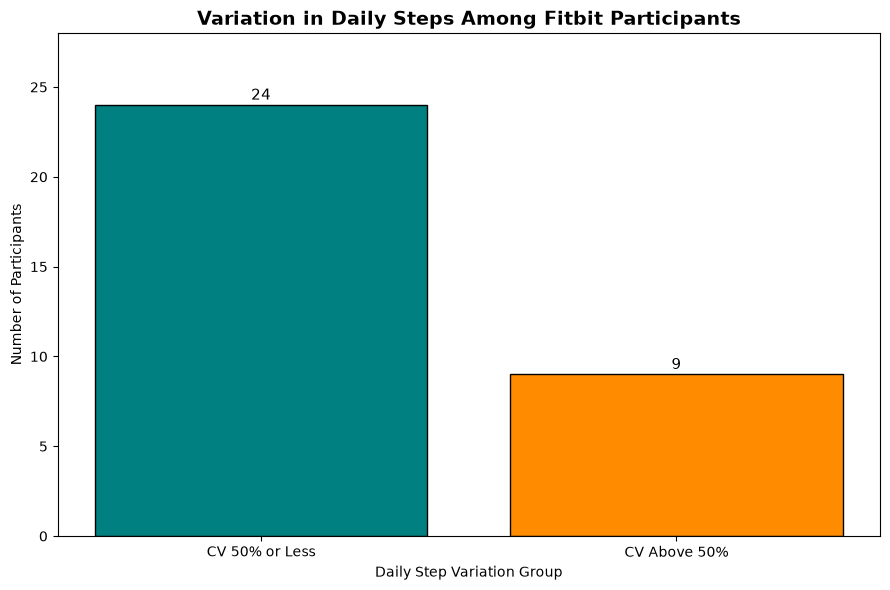

In [111]:

# Share Visualization 4: Daily Step Consistency

cv_values = nonzero_step_consistency["CV_Percent"]

consistency_counts = [
    (cv_values <= 50).sum(),
    (cv_values > 50).sum()
]

labels = [
    "CV 50% or Less",
    "CV Above 50%"
]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    labels,
    consistency_counts,
    color=["teal", "darkorange"],
    edgecolor="black"
)

plt.title(
    "Variation in Daily Steps Among Fitbit Participants",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Daily Step Variation Group")
plt.ylabel("Number of Participants")
plt.ylim(0, max(consistency_counts) + 4)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        str(int(bar.get_height())),
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()


### Visualization 4: Activity Consistency

This bar chart compares the variation in daily step counts among the 33 Fitbit participants, using the coefficient of variation (CV).

After excluding zero-step days, 24 participants (72.7%) had a CV of 50% or less, while 9 participants (27.3%) had a CV above 50%.

These findings show that daily step consistency varied across participants. Although most fell into the lower-variation group, approximately one-quarter showed greater variation in their recorded activity.

**Marketing insight:** Bellabeat could explore promoting consistent wellness habits through personalized activity goals, progress summaries, and encouraging reminders. Messaging could focus on making gradual progress rather than expecting users to achieve the same activity level every day.

**Limitation:** The 50% CV threshold was selected for exploratory analysis and is not an established fitness classification. Excluding zero-step days reduces the influence of potentially incomplete tracking records but may also exclude genuine inactive days. The results do not establish why participants' activity levels varied.

### Share Phase Summary

During the Share phase, I created four visualizations to communicate the most important findings from my analysis of Fitbit activity and sleep data.

**Key Findings**

1. **Daily Activity:** Approximately 32% of recorded days had fewer than 5,000 steps, showing that lower-activity days were common in the dataset.

2. **Activity Levels:** More than half of the participants (18 out of 33) fell into the moderate-activity group based on their average daily steps. This suggests an opportunity to explore activity goals tailored to different users.

3. **Sleep Duration:** Approximately 44% of recorded nights had fewer than seven hours of sleep. This highlights sleep awareness as a potential area for Bellabeat's wellness messaging.

4. **Activity Consistency:** After excluding zero-step days, 9 of the 33 participants had a coefficient of variation above 50%. This suggests that some participants experienced greater day-to-day variation in their recorded activity.

**Overall Interpretation**

These findings suggest that Bellabeat could explore marketing strategies that focus on achievable activity goals, consistent wellness habits, and sleep awareness.

Rather than emphasizing high performance alone, Bellabeat could position the Leaf as a tool that supports users in understanding their daily routines and making gradual progress toward their personal wellness goals.

**Important Limitations**

The Fitbit dataset represents a small, historical sample and may include incomplete tracking records. The activity categories and consistency thresholds were created for exploratory analysis. These findings identify potential marketing opportunities but do not establish customer preferences, product effectiveness, or causal relationships.

The next phase will use these findings to develop three data-informed marketing recommendations for Bellabeat.

## Step 6: Act

### Final Marketing Recommendations for Bellabeat

The purpose of this phase is to turn my analysis into actionable marketing recommendations for Bellabeat.

After examining Fitbit activity and sleep data, I identified three areas that Bellabeat could explore to better connect with potential customers and communicate the value of the Bellabeat Leaf.

My recommendations will focus on:

1. Personalized activity goals
2. Building consistent wellness habits
3. Sleep tracking and awareness

For each recommendation, I will explain the supporting data, suggest a marketing strategy, and identify ways Bellabeat could evaluate its effectiveness.

Because this analysis uses a small historical sample of Fitbit users, these recommendations should be treated as opportunities to test rather than proven strategies.

### Marketing Recommendation 1: Promote Personalized Activity Goals

**What the Data Shows**

My analysis found that Fitbit participants averaged approximately 7,638 steps per recorded day, and 32% of recorded days had fewer than 5,000 steps.

I also found that 18 of the 33 participants (54.5%) fell into the moderate-activity group based on their average daily steps.

These findings show that recorded activity levels varied across the sample.

**My Recommendation**

I recommend that Bellabeat test a marketing campaign focused on personalized activity goals and gradual progress.

Rather than encouraging everyone to reach the same daily step count, Bellabeat could emphasize how wellness tracking can help users understand their current activity levels and work toward realistic personal goals.

**Suggested Marketing Strategy**

Bellabeat could develop social media and email campaigns featuring messages such as:

*“Your wellness journey starts with your own goals.”*

Campaign content could highlight everyday activities, manageable goals, and the value of recognizing personal progress.

Bellabeat should confirm which goal-setting and activity-tracking capabilities are supported by the Leaf and its companion app before making specific product claims.

**How Bellabeat Could Measure Success**

Bellabeat could evaluate this campaign by tracking:

- Engagement rates on activity-focused marketing content.
- Click-through rates to product or activity-tracking information.
- Conversion rates among customers exposed to personalized-goal messaging.

An A/B test comparing personalized-goal messaging with general activity messaging could help determine which approach performs better.

**Why This Recommendation Matters**

The Fitbit data suggests that activity levels differ among users. Marketing that recognizes these differences could make Bellabeat's messaging more relatable to a wider range of potential customers.

However, the dataset does not establish which marketing messages customers prefer. Bellabeat would need to test this strategy with its target audience.

### Marketing Recommendation 2: Encourage Consistent Wellness Habits

**What the Data Shows**

My analysis found that daily step counts varied across Fitbit participants.

After excluding zero-step days, 9 of the 33 participants (27.3%) had a coefficient of variation above 50%, indicating relatively high variation in their recorded daily activity.

The median coefficient of variation was approximately 40.38%, showing that day-to-day activity variation was present across the sample.

These findings suggest that maintaining the same activity level every day may not reflect how people actually approach their routines.

**My Recommendation**

I recommend that Bellabeat test a marketing campaign focused on building consistent, realistic wellness habits rather than achieving perfect results every day.

The campaign could encourage users to recognize small improvements, develop manageable routines, and view wellness as an ongoing process.

**Suggested Marketing Strategy**

Bellabeat could create a social media and email campaign centered on the message:

*“Progress, not perfection.”*

Marketing content could feature realistic examples of daily wellness routines, such as taking a short walk, setting aside time to unwind, or reflecting on personal progress.

Bellabeat could also explore educational content about developing sustainable habits and using available tracking information to understand changes over time.

Any promotional claims about reminders, progress summaries, or habit-tracking features should be verified against the Leaf's actual capabilities.

**How Bellabeat Could Measure Success**

Bellabeat could evaluate the campaign by measuring:

- Engagement rates on habit-building content.
- Click-through rates from campaign messages to Bellabeat's website.
- Email sign-ups or other campaign conversions.
- Differences in conversion rates between habit-focused messaging and general wellness messaging.

Bellabeat could use an A/B test to determine whether habit-building messages generate stronger engagement or conversions.

**Why This Recommendation Matters**

The Fitbit data shows that recorded activity levels were not equally consistent across participants.

A campaign emphasizing flexibility and gradual progress could make Bellabeat's wellness messaging more approachable for potential customers who do not maintain the same routine every day.

However, the analysis does not explain why activity levels varied or establish that these participants would prefer habit-focused messaging. Bellabeat would need to test the campaign with its target audience before drawing conclusions about its effectiveness.

### Marketing Recommendation 3: Promote Sleep Tracking and Awareness

**What the Data Shows**

My analysis of the Fitbit sleep dataset included 410 records from 24 participants.

I found that 181 of the 410 recorded nights (44.1%) had fewer than seven hours of sleep. Average recorded sleep efficiency was approximately 92%.

These findings show that recorded sleep duration varied and that a substantial portion of recorded nights fell below the seven-hour reference point.

**My Recommendation**

I recommend that Bellabeat test a marketing campaign highlighting the importance of understanding personal sleep patterns as part of an overall wellness routine.

The campaign could emphasize how tracking sleep trends may help users become more aware of their habits and make informed decisions about their routines.

**Suggested Marketing Strategy**

Bellabeat could develop educational social media posts, email content, and short videos centered on the message:

*“Better wellness starts with understanding your rest.”*

Campaign content could explain the difference between sleep duration and sleep efficiency, encourage awareness of bedtime routines, and demonstrate any relevant sleep-tracking features supported by the Bellabeat Leaf.

Bellabeat should verify the Leaf's current sleep-tracking capabilities before making specific product claims.

**How Bellabeat Could Measure Success**

Bellabeat could measure the campaign's performance through:

- Engagement rates on sleep-focused educational content.
- Click-through rates to sleep-tracking product information.
- Email sign-ups or other campaign conversions.
- Conversion rates for sleep-focused messaging compared with general wellness messaging.

An A/B test could help determine whether sleep-focused marketing generates stronger interest among Bellabeat's target audience.

**Why This Recommendation Matters**

The Fitbit data suggests that shorter recorded sleep durations were relatively common within the sample.

By including sleep awareness in its marketing, Bellabeat could explore positioning the Leaf as part of a balanced wellness routine that considers both activity and rest.

However, these records do not establish participants' sleep needs, explain why some nights were shorter, or demonstrate that sleep-focused marketing would improve customer engagement. Bellabeat would need additional customer research and campaign testing to evaluate this recommendation.

## Final Case Study Conclusion

The goal of this case study was to analyze smart device usage data and identify trends that could help Bellabeat develop marketing strategies for the Bellabeat Leaf wellness tracker.

Using Python and pandas, I cleaned, organized, and analyzed Fitbit activity and sleep data. I explored daily step counts, activity levels, activity consistency, sleep duration, and sleep efficiency. I also created visualizations to communicate the most important findings.

My analysis revealed several patterns. Approximately 32% of recorded activity days had fewer than 5,000 steps, and more than half of the participants fell into the moderate-activity group. I also found differences in daily activity consistency, with some participants showing greater variation in their step counts than others.

Sleep was another important area of the analysis. Approximately 44% of recorded nights had fewer than seven hours of sleep, suggesting that sleep awareness could be a useful topic for wellness-focused marketing.

Based on these findings, I developed three recommendations for Bellabeat:

1. **Promote personalized activity goals** that encourage users to work toward realistic goals based on their individual activity levels.
2. **Encourage consistent wellness habits** through messaging that focuses on gradual progress rather than perfection.
3. **Highlight sleep tracking and awareness** as part of a balanced approach to personal wellness.

These recommendations could help Bellabeat explore ways to connect with potential customers through relatable, educational, and personalized marketing campaigns.

However, the dataset was limited to a small sample of Fitbit users over approximately one month in 2016. Some records may reflect incomplete tracking, and the findings cannot be assumed to represent Bellabeat's current customers.

As a next step, I would recommend that Bellabeat test these marketing strategies with its target audience and compare the results using engagement, click-through, and conversion rates. This would help the company determine which messages connect most effectively with potential customers and make more informed marketing decisions.

**My Final Takeaway**

This project showed me how data analysis can be used to move from raw information to meaningful business recommendations. By cleaning the data, examining patterns, creating visualizations, and considering limitations, I was able to identify potential marketing opportunities supported by the available evidence.

The next step for Bellabeat would be to validate these opportunities through customer research and controlled marketing experiments before making larger marketing decisions.